# Web APIs 第三天：DOM 事件进阶

## 0. 本篇资料与学习目标

本篇对应 JavaScript 课程第 08 篇，即 **Web APIs 第三天**。按讲义顺序先练习全选复选框，再学习事件流、事件委托、页面加载与滚动、元素尺寸与位置，最后完成电梯导航。

主要资料是用户提供的[百度网盘分享](https://pan.baidu.com/s/1MxueOHXGQtmE-ypRq1kELA?pwd=9987)，提取码 `9987`，目录为 `2.web APIs → 资料 → web APIs第三天`。已读取 `web APIs第三天.pdf` 的全部 68 页公开预览，包括图中代码。

网盘配套源码下载要求登录。下面标为“同课公开练习代码”的内容来自 [wukaihang/pink-javascript](https://github.com/wukaihang/pink-javascript/tree/main/2.Web%20APIs/day3)，用于对照讲义，**属于公开练习副本**。其代码、注释和启用状态原样保留；与讲义不同或有问题的地方就地说明。“整理示例”是依据讲义步骤补出的可读示例。网盘作业目录已核实，尚未取得的作业正文在末尾注明。

本日要解决两个问题：怎样减少重复的事件绑定；怎样把事件、滚动距离与元素位置连接起来，实现常见网页交互。

## 1. 课前练习：全选复选框

### 1.1 大复选框控制小复选框

页面有一个全选框 `#checkAll`，每个商品有一个 `.ck` 小复选框。点击大框后，把它的 `checked` 状态赋给全部小框：选中时都为 `true`，取消时都为 `false`。`checked` 是布尔属性，不能写成字符串 `'false'`。

### 1.2 小复选框反过来控制全选框

每次点击小框，都重新查询 `.ck:checked` 的数量。只有选中数量等于小框总数，大框才选中。

`querySelectorAll()` 返回的是静态集合。原代码在每次点击时重新查询选中项，才能得到最新数量；初始化时获取的 `cks` 用来表示这个固定页面的小框总数。

同课公开练习的完整页面（`01-全选按钮案例.html`）：

```html
<!DOCTYPE html>

<html>

<head lang="en">
  <meta charset="UTF-8">
  <title></title>
  <style>
    * {
      margin: 0;
      padding: 0;
    }

    table {
      border-collapse: collapse;
      border-spacing: 0;
      border: 1px solid #c0c0c0;
      width: 500px;
      margin: 100px auto;
      text-align: center;
    }

    th {
      background-color: #09c;
      font: bold 16px "微软雅黑";
      color: #fff;
      height: 24px;
    }

    td {
      border: 1px solid #d0d0d0;
      color: #404060;
      padding: 10px;
    }

    .allCheck {
      width: 80px;
    }
  </style>
</head>

<body>
  <table>
    <tr>
      <th class="allCheck">
        <input type="checkbox" name="" id="checkAll"> <span class="all">全选</span>
      </th>
      <th>商品</th>
      <th>商家</th>
      <th>价格</th>
    </tr>
    <tr>
      <td>
        <input type="checkbox" name="check" class="ck">
      </td>
      <td>小米手机</td>
      <td>小米</td>
      <td>￥1999</td>
    </tr>
    <tr>
      <td>
        <input type="checkbox" name="check" class="ck">
      </td>
      <td>小米净水器</td>
      <td>小米</td>
      <td>￥4999</td>
    </tr>
    <tr>
      <td>
        <input type="checkbox" name="check" class="ck">
      </td>
      <td>小米电视</td>
      <td>小米</td>
      <td>￥5999</td>
    </tr>
  </table>
  <script>
    // 1. 获取大复选框
    const checkAll = document.querySelector('#checkAll')
    // 2. 获取所有的小复选框
    const cks = document.querySelectorAll('.ck')
    // 3. 点击大复选框  注册事件
    checkAll.addEventListener('click', function () {
      // 得到当前大复选框的选中状态
      // console.log(checkAll.checked)  // 得到 是 true 或者是 false
      // 4. 遍历所有的小复选框 让小复选框的checked  =  大复选框的 checked
      for (let i = 0; i < cks.length; i++) {
        cks[i].checked = this.checked
      }
    })
    // 5. 小复选框控制大复选框

    for (let i = 0; i < cks.length; i++) {
      // 5.1 给所有的小复选框添加点击事件
      cks[i].addEventListener('click', function () {
        // 判断选中的小复选框个数 是不是等于  总的小复选框个数
        // 一定要写到点击里面，因为每次要获得最新的个数 
        // console.log(document.querySelectorAll('.ck:checked').length)
        // console.log(document.querySelectorAll('.ck:checked').length === cks.length)
        // 先判断是否全等再赋值
        // .ck:checked  选中的小复选框 伪类选择器
        checkAll.checked = document.querySelectorAll('.ck:checked').length === cks.length
      })
    }

    // cks.forEach(ck => {
    //   ck.addEventListener('click', function () {
    //     checkAll.checked = document.querySelectorAll('.ck:checked').length === cks.length
    //   })
    // })
  </script>
</body>

</html>
```

在浏览器打开这个 HTML：勾选大框应选中三件商品；取消其中一件，大框自动取消；再勾选该商品，大框自动恢复。

### 1.3 讲义要求的文字同步

讲义还要求“文字对应变化”，公开练习已有 `<span class="all">全选</span>`，但脚本未更新文字。下面是这一要求的**整理示例**：使用与上例相同的 HTML，替换上例整个 `<script>`，不要同时保留两套绑定。

```javascript
const checkAll = document.querySelector('#checkAll')
const cks = document.querySelectorAll('.ck')
const all = document.querySelector('.all')

function updateText() {
  all.innerText = checkAll.checked ? '取消全选' : '全选'
}

checkAll.addEventListener('click', function () {
  for (let i = 0; i < cks.length; i++) {
    cks[i].checked = this.checked
  }
  updateText()
})

for (let i = 0; i < cks.length; i++) {
  cks[i].addEventListener('click', function () {
    checkAll.checked = document.querySelectorAll('.ck:checked').length === cks.length
    updateText()
  })
}
updateText()
```

这里的“取消全选”是全部取消，和把每个小框状态取反的“反选”不同。讲义末尾称练习为“全选反选”，本例实际演示的是全选、全部取消以及小框反控大框。

## 2. 事件流

### 2.1 一次点击怎样沿 DOM 流动

**事件流**是一次事件经过的完整路径。点击嵌套盒子的子元素时，可以观察从外到内的捕获，再观察从内到外的冒泡。

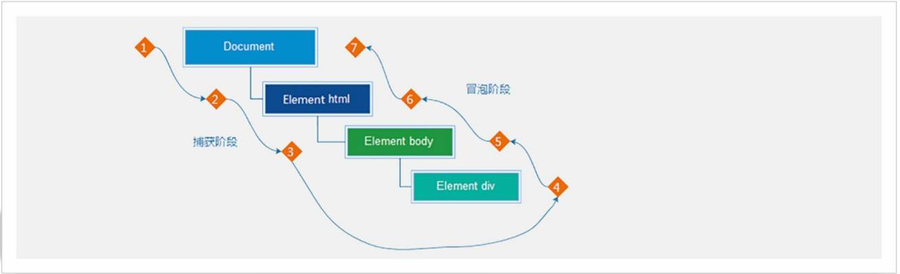

讲义把重点概括成两个方向：捕获从父到子，冒泡从子到父。补充：完整 DOM 事件过程还包含中间的**目标阶段**，目标元素上的监听器在目标阶段执行；图示从 `document` 开始，浏览器中的路径通常还包括 `window`。

实际开发常使用冒泡，但并非所有事件都会冒泡。本课稍后会比较 `mouseover` 与 `mouseenter`。

### 2.2 捕获、冒泡和阻止传播的对照练习

`addEventListener()` 的第三个参数决定监听的阶段：

```javascript
元素.addEventListener('click', 事件处理函数, true)  // 捕获
元素.addEventListener('click', 事件处理函数, false) // 冒泡，默认值
```

同课公开练习 `03-事件流(事件捕获与事件冒泡).html` 保留了三组代码。捕获与普通冒泡两组被注释，当前启用的是阻止冒泡：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
  <style>
    .fa {
      width: 200px;
      height: 200px;
      background-color: pink;
    }

    .son {
      width: 100px;
      height: 100px;
      background-color: red;
    }
  </style>
</head>

<body>
  <div class="fa">
    <div class="son"></div>
  </div>
  <script>
    const fa = document.querySelector('.fa')
    const son = document.querySelector('.son')
    // // 事件捕获
    // // 事件捕获是从document开始，逐级向下查找，直到找到目标元素
    // // addEventListener第三个参数如果是true，就是事件捕获，默认是false，事件冒泡
    // document.addEventListener('click', function () {
    //   alert('document')
    // }, true)
    // fa.addEventListener('click', function () {
    //   alert('fa')
    // }, true)
    // son.addEventListener('click', function () {
    //   alert('son')
    // }, true)

    // // 事件冒泡
    // // 当一个元素的事件被触发时，同样的事件（同名事件） 会在该元素的所有祖先元素中依次被触发
    // // 事件冒泡是从目标元素开始，逐级向上冒泡，直到document
    // document.addEventListener('click', function () {
    //   alert('document')
    // })
    // fa.addEventListener('click', function () {
    //   alert('fa')
    // })
    // son.addEventListener('click', function () {
    //   alert('son')
    // })

    // 阻止冒泡
    // 事件冒泡的过程中，每个元素的事件处理函数都会被调用
    // 但是，我们可以在事件处理函数中调用事件对象的stopPropagation方法，来阻止事件冒泡
    son.addEventListener('click', function (e) {
      alert('son')
      // 阻止流动传播（事件冒泡或事件捕获）
      // 事件对象.stopPropagation()
      e.stopPropagation()
    })
    fa.addEventListener('click', function () {
      alert('fa')
    })
    document.addEventListener('click', function () {
      alert('document')
    })
  </script>
</body>

</html>
```

按以下顺序观察，**每次只启用一组监听代码**，避免把三组同时运行：

| 启用的代码 | 点击红色 `.son` 后的提示顺序 |
| --- | --- |
| 捕获组，第三个参数为 `true` | `document → fa → son` |
| 冒泡组，不写第三个参数 | `son → fa → document` |
| 当前启用的阻止冒泡组 | 只有 `son` |

点击粉色父盒子的空白区域，目标就是父盒子，不会执行子盒子的监听。事件传播只经过事件路径上的元素，不会传播到兄弟元素。

### 2.3 `stopPropagation()` 阻止传播

有时点击子元素只应处理子元素自身，不希望继续触发祖先上的同名监听。需要先取得事件对象 `e`，再调用：

```javascript
e.stopPropagation()
```

它阻止事件继续沿路径传播，捕获阶段也有效。如果在父元素的捕获监听中阻断，事件就不能继续到达内部子元素。它不会取消浏览器默认行为，也不会阻止同一元素上其他已注册监听器继续执行。

### 2.4 `preventDefault()` 阻止默认行为

链接默认会跳转，表单默认会提交。需要保留点击或提交事件处理，同时取消默认动作时，用 `e.preventDefault()`。

同课公开练习 `10-阻止默认行为.html`：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>

</head>

<body>
  <form action="http://www.itcast.cn">
    <input type="submit" value="免费注册">
  </form>
  <a href="http://www.baidu.com">百度一下</a>
  <script>
    const form = document.querySelector('form')
    form.addEventListener('submit', function (e) {
      e.preventDefault()
    })
    const a = document.querySelector('a')
    a.addEventListener('click', function (e) {
      e.preventDefault()
    })
  </script>
</body>

</html>
```

点击“百度一下”应停留在原页面；点击“免费注册”应取消表单默认提交。代码没有调用 `stopPropagation()`，事件仍可以传播给祖先。

| 方法 | 当前要解决的问题 |
| --- | --- |
| `e.stopPropagation()` | 子元素事件继续传播到祖先 |
| `e.preventDefault()` | 链接跳转、表单提交等默认动作 |

### 2.5 解绑事件

传统 `on` 属性方式（课程称 L0）可直接赋 `null`：

```javascript
btn.onclick = null
```

`addEventListener()` 方式（课程称 L2）用 `removeEventListener()`，必须提供相同的事件类型、**同一个函数引用**和相同的捕获标记：

```javascript
btn.addEventListener('click', fn, false)
btn.removeEventListener('click', fn, false)
```

同课公开练习 `05-解绑事件.html`：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <button>点击</button>
  <script>
    const btn = document.querySelector('button')
    // btn.onclick = function () {
    //   alert('点击了按钮')
    //   // 解绑事件 （Level 0 写法）
    //   // 点击按钮后，再点击按钮，没有任何响应
    //   btn.onclick = null
    // }

    function fn() {
      alert('点击了按钮')
    }

    btn.addEventListener('click', fn)
    // 解绑事件 （Level 2 写法）
    // 点击按钮后，再点击按钮，没有任何响应
    // 匿名函数无法被解绑
    btn.removeEventListener('click', fn)
  </script>
</body>

</html>
```

> 原代码在注册后立刻解绑，尚未发生点击，所以运行后连第一次点击也不会弹窗。注释写的“点击按钮后，再点击没有响应”对应的是被注释的 L0 版本，不能用它解释当前 L2 版本。

若想“第一次点击后解绑”，这是对应的**修正示例**，用来替换上例脚本：

```javascript
const btn = document.querySelector('button')
function fn() {
  alert('点击了按钮')
  btn.removeEventListener('click', fn)
}
btn.addEventListener('click', fn)
```

讲义说“匿名函数无法解绑”，具体指直接传入且没有保存引用的匿名回调。保存函数引用后，即使它没有函数名，也可以解绑；重新写一个看起来相同的函数不是同一个引用。

### 2.6 鼠标经过事件的区别

| 事件 | 含义 | 是否冒泡 |
| --- | --- | --- |
| `mouseover` / `mouseout` | 鼠标进入 / 离开元素，内部子元素变化也可能触发 | 是 |
| `mouseenter` / `mouseleave` | 鼠标进入 / 离开整个元素区域 | 否 |

同课公开练习 `06-mauseover和mouseenter的区别.html`（文件名保留原拼写）：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
  <style>
    .dad {
      width: 200px;
      height: 200px;
      background-color: pink;
    }

    .son {
      width: 100px;
      height: 100px;
      background-color: red;
    }
  </style>
</head>

<body>
  <div class="dad">
    <div class="son"></div>
  </div>

  <script>
    const dad = document.querySelector('.dad')
    const son = document.querySelector('.son')
    // mouseenter 和 mouseleave 不会冒泡
    // mouseover 和 mouseout 会冒泡
    dad.addEventListener('mouseenter', function () {
      console.log('鼠标经过')
    })
    dad.addEventListener('mouseleave', function () {
      console.log('鼠标离开')
    })
  </script>
</body>

</html>
```

鼠标从外部进入父盒子，会输出“鼠标经过”；在父盒子内移动到红色子盒子，不会再次触发父盒子的 `mouseenter`。离开整个父盒子才输出“鼠标离开”。把事件改为 `mouseover` / `mouseout` 做对照，移动到子盒子时会观察到更多父级回调。

### 2.7 两种注册方式的区别

| 比较项 | `onclick` 等 L0 方式 | `addEventListener()` L2 方式 |
| --- | --- | --- |
| 同一元素、同一种事件，多次注册 | 后面的赋值覆盖前面的属性处理函数 | 可注册多个不同监听器 |
| 捕获监听 | 不能选择捕获 | 第三个参数为 `true` 可选择捕获 |
| 解绑 | 对应 `on` 属性赋 `null` | `removeEventListener()` |
| 解绑所需函数引用 | 不需要 | 需要原函数引用，捕获标记也要匹配 |

讲义称 L0“都是冒泡阶段执行”，学习时理解为不能选择捕获即可：目标元素上的 L0 回调仍在目标阶段执行。

## 3. 事件委托

### 3.1 把子元素的事件委托给父元素

给五个列表项各绑定一次点击，需要循环注册五次。借助冒泡，可只在父级 `ul` 注册一次，然后判断真实点击的是哪个子元素。这个技巧叫**事件委托**。

同课公开练习 `07-事件委托(e.target).html`：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <ul>
    <li>第1个孩子</li>
    <li>第2个孩子</li>
    <li>第3个孩子</li>
    <li>第4个孩子</li>
    <li>第5个孩子</li>
    <p>我不需要变色</p>
  </ul>

  <script>
    // 按照事件委托的方式 委托给父元素 事件写在父元素身上
    // 子元素类型相同 且都要添加同一事件 的时候适合用事件委托
    const ul = document.querySelector('ul')
    // 点击li 更改li文本颜色
    ul.addEventListener('click', function (e) {
      // e.target 是事件触发的元素（点击的li）
      console.log(e.target)
      // 更改li文本颜色
      if (e.target.tagName === 'LI') {
        e.target.style.color = 'red'
      }
    })
  </script>
</body>

</html>
```

在普通 HTML 元素上，`tagName` 返回大写标签名，因此代码判断 `'LI'`。点击列表项，其文字变红；点击“我不需要变色”或列表空白处，应保持原样。

原页面在 `ul` 内直接放了 `p`，用来演示目标过滤。规范列表结构应让 `ul` 的列表内容由 `li` 组织；此处保留练习原结构。

| 取值 | 在本例中的意义 |
| --- | --- |
| `e.target` | 真正触发点击的元素，可能是 `li`、`p` 或 `ul` |
| `e.currentTarget` | 当前执行监听器的元素，本例为 `ul` |
| 普通函数回调中的 `this` | 本例为注册监听的 `ul` |

委托减少了监听器数量，也能处理后来添加到父级中的同类子元素。前提是对应事件能传播到父级，且代码正确过滤目标。本例的列表项只有直接文字；若内部再嵌套其他标签，直接判断 `e.target.tagName` 就只匹配实际点到的那个标签。

### 3.2 自定义属性保存编号

循环绑定时可使用循环变量 `i`，改成父级委托后就没有那个逐项注册时的索引了。讲义用 `data-id` 保存每个链接的序号，通过 `dataset.id` 读取。

同课公开练习 `09-自定义属性.html`：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
</head>

<body>
  <div data-id="0"></div>
  <script>
    const div = document.querySelector('div')
    console.log(div.dataset.id)
  </script>
</body>

</html>
```

注意 `dataset` 的值是**字符串**。`data-id="0"` 读出来是 `'0'`，做加法前先转为数字。

### 3.3 把 Tab 切换改为事件委托

需求：点击一个导航链接，只让该链接和对应内容面板带有 `active`。按照讲义先委托，再过滤 `A`，最后分别对导航和内容执行排他操作。

1. 给 `.tab-nav ul` 注册点击。
2. 只处理 `e.target.tagName === 'A'` 的目标。
3. 删除旧导航的 `active`，给当前链接添加。
4. 读取链接的 `data-id`，删除旧内容的 `active`，选择对应内容。

同课公开练习 `08-tab栏切换.html`：

```html
<!DOCTYPE html>
<html lang="en">

<head>
  <meta charset="UTF-8" />
  <meta http-equiv="X-UA-Compatible" content="IE=edge" />
  <meta name="viewport" content="width=device-width, initial-scale=1.0" />
  <title>tab栏切换</title>
  <style>
    * {
      margin: 0;
      padding: 0;
    }

    .tab {
      width: 590px;
      height: 340px;
      margin: 20px;
      border: 1px solid #e4e4e4;
    }

    .tab-nav {
      width: 100%;
      height: 60px;
      line-height: 60px;
      display: flex;
      justify-content: space-between;
    }

    .tab-nav h3 {
      font-size: 24px;
      font-weight: normal;
      margin-left: 20px;
    }

    .tab-nav ul {
      list-style: none;
      display: flex;
      justify-content: flex-end;
    }

    .tab-nav ul li {
      margin: 0 20px;
      font-size: 14px;
    }

    .tab-nav ul li a {
      text-decoration: none;
      border-bottom: 2px solid transparent;
      color: #333;
    }

    .tab-nav ul li a.active {
      border-color: #e1251b;
      color: #e1251b;
    }

    .tab-content {
      padding: 0 16px;
    }

    .tab-content .item {
      display: none;
    }

    .tab-content .item.active {
      display: block;
    }
  </style>
</head>

<body>
  <div class="tab">
    <div class="tab-nav">
      <h3>每日特价</h3>
      <ul>
        <li><a class="active" href="javascript:;" data-id="0">精选</a></li>
        <li><a href="javascript:;" data-id="1">美食</a></li>
        <li><a href="javascript:;" data-id="2">百货</a></li>
        <li><a href="javascript:;" data-id="3">个护</a></li>
        <li><a href="javascript:;" data-id="4">预告</a></li>
      </ul>
    </div>
    <div class="tab-content">
      <div class="item active"><img src="./images/tab00.png" alt="" /></div>
      <div class="item"><img src="./images/tab01.png" alt="" /></div>
      <div class="item"><img src="./images/tab02.png" alt="" /></div>
      <div class="item"><img src="./images/tab03.png" alt="" /></div>
      <div class="item"><img src="./images/tab04.png" alt="" /></div>
    </div>
  </div>

  <script>
    // 采取事件委托的方式
    const ul = document.querySelector('.tab-nav ul')
    // 点击li 切换类名
    ul.addEventListener('click', function (e) {
      console.log(e.target)
      // 只有点击a标签才切换类名
      if (e.target.tagName === 'A') {
        // 先把所有a的类名移除
        document.querySelector('.tab-nav .active').classList.remove('active')
        // this指向ul，不能用this
        e.target.classList.add('active')
        // 通过自定义属性获取当前点击的是第几个
        // console.log(e.target.dataset.id)
        // 先把所有item的active类名移除
        document.querySelector('.tab-content .active').classList.remove('active')
        // 给当前点击的item添加类名
        document.querySelector(`.tab-content .item:nth-child(${Number(e.target.dataset.id) + 1})`).classList.add('active')
      }
    })
  </script>
</body>

</html>
```

`data-id` 从 `0` 开始，CSS 的 `:nth-child()` 从 `1` 开始，所以用 `Number(e.target.dataset.id) + 1`。若省略 `Number()`，字符串 `'0' + 1` 会得到 `'01'`，其他编号也会发生字符串拼接，选不中预期面板。

原页面初始已在一个导航链接、一个 `.item` 上设置 `active`，所以这里可直接获取旧状态并删除；没有初始选中项的场景要判断 `null`，后面的电梯导航会处理。

测试五个链接应分别显示五张图，每次导航和内容都只有一个 `active`。点击 `h3`、`li` 的空白位置不应切换。原代码使用 `href="javascript:;"` 防止链接跳转。图片需沿用练习的 `images/tab00.png` 至 `tab04.png` 相对目录。

## 4. 其他事件

### 4.1 页面加载：`load` 与 `DOMContentLoaded`

把脚本放在 `head`，如果立刻查找后面的按钮，HTML 还没解析到按钮，查询就会得到 `null`。把操作放进加载事件回调，可等到对应的加载阶段再取得元素。

| 事件 | 注册对象 | 本课关注的触发时机 |
| --- | --- | --- |
| `load` | `window` | 页面及相关外部资源加载完成 |
| `DOMContentLoaded` | `document` | HTML 解析完成，DOM 已可使用 |
| 某个资源的 `load` | 例如图片元素 | 该资源自身加载完成 |

同课公开练习 `11-页面加载事件.html`，脚本确实放在 `head` 中：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
  <script>
    // 等待页面所有资源加载完毕后执行回调函数
    window.addEventListener('load', function () {
      const btn = document.querySelector('button')
      btn.addEventListener('click', function () {
        alert('点击了按钮')
      })
    })

    // 等待图片加载完毕后执行回调函数
    // img.addEventListener('load', function() {
    //   console.log('图片加载完毕')
    // })

    // 等待DOM树加载完毕后执行回调函数(给 document 添加)
    document.addEventListener('DOMContentLoaded', function () {
      console.log('DOM树加载完毕')
    })
  </script>
</head>

<body>
  <button>点击</button>
</body>

</html>
```

页面加载后，点击按钮会弹窗；控制台会先输出“DOM树加载完毕”。图片 `load` 示例保留为注释，实际使用前需要取得 `img` 元素。

讲义用“无需等待样式表、图像等完全加载”解释 `DOMContentLoaded`。补充边界：它不直接等待图片等资源，但会等待需在此之前执行的延迟脚本，相关脚本也可能受样式表加载影响；不应把它理解成完全不受 CSS 或脚本影响。

### 4.2 滚动事件与被卷去的距离

`scroll` 在滚动位置发生变化时触发。页面滚动给 `window` 或 `document` 注册；盒子内部滚动给该盒子注册，盒子需要有溢出的内容和可滚动布局。

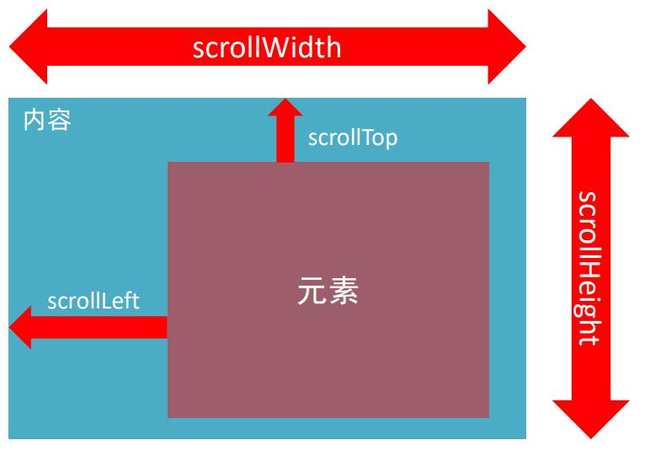

| 属性 | 表示什么 | 是否可赋值 |
| --- | --- | --- |
| `scrollTop` | 内容向上滚出可见区域的距离 | 是 |
| `scrollLeft` | 内容向左滚出可见区域的距离 | 是 |

返回值为数字，单位按像素理解，不含 `'px'`。尽量在 `scroll` 回调中读取，取得当前距离。图中的 `scrollWidth` / `scrollHeight` 表示滚动内容范围，不是已滚动的距离。

讲义的盒子滚动写法（据原图）：

```javascript
div.addEventListener('scroll', function () {
  console.log(this.scrollTop)
})
```

课程页面使用标准 HTML 文档，通过 `document.documentElement` 取得根 `html` 元素，并读取它的 `scrollTop`：

```javascript
window.addEventListener('scroll', function () {
  console.log(document.documentElement.scrollTop)
})
```

### 4.3 公开练习：滚动 100 像素显示盒子

同课公开练习 `12-页面滚动事件.html` 的脚本：

```javascript
    const div = document.querySelector('div')
    // 页面滚动事件
    window.addEventListener('scroll', function () {
      // console.log('页面滚动了')
      // 获取 html 元素  document.documentElement
      // console.log(document.documentElement)
      const n = document.documentElement.scrollTop
      if (n >= 100) {
        div.style.display = 'block'
      }
      else {
        div.style.display = 'none'
      }
    })

    // div.addEventListener('scroll', function () {
    //   // console.log('div滚动了')
    //   // div被卷去的头部 scrollTop 单位是像素
    //   // div被卷去的左边 scrollLeft 单位是像素
    //   console.log(div.scrollTop)
    // })
  
```

其样式原代码：

```css
    body {
      margin: 300px 0;
      ;
      height: 2000px;
    }

    div {
      display: none;
      height: 200px;
      width: 200px;
      border: 1px solid #e4e4e4;
      margin: 100px;
      overflow: scroll;
    }
  
```

页面 `body` 有足够高度，`div` 初始 `display: none`，内部有多段文字。页面滚动到 `n >= 100` 时显示盒子，回到 100 以下隐藏。盒子自身的滚动监听被注释，取消那部分注释才会输出 `div.scrollTop`。

这份练习与讲义后面的侧边栏案例不同：它的阈值是 **100**，使用 `display` 显隐；讲义要求大于 **300**，使用 `opacity` 配合过渡。

### 4.4 讲义案例：滚动显示、隐藏侧边栏

需求：页面滚动距离大于 300 像素时显示侧边栏，否则隐藏，并产生渐变效果。核心是 `scroll` 中判断 `document.documentElement.scrollTop`，把结果用于 `opacity`。

下面是依据讲义的**整理示例**，保存为独立 HTML 即可观察：

```html
<!DOCTYPE html>
<html lang="zh-CN">
<head>
  <meta charset="UTF-8">
  <title>侧边栏与返回顶部</title>
  <style>
    body { height: 3000px; }
    .backtop {
      position: fixed;
      right: 30px;
      bottom: 60px;
      opacity: 0;
      transition: opacity .3s;
    }
  </style>
</head>
<body>
  <p>向下滚动超过 300 像素，观察右下方按钮。</p>
  <button class="backtop">返回顶部</button>
  <script>
    const backtop = document.querySelector('.backtop')
    window.addEventListener('scroll', function () {
      const n = document.documentElement.scrollTop
      backtop.style.opacity = n > 300 ? 1 : 0
    })
    backtop.addEventListener('click', function () {
      document.documentElement.scrollTop = 0
    })
  </script>
</body>
</html>
```

300 像素时仍隐藏，超过 300 才显示；回到顶部应隐藏。`opacity: 0` 只改变透明度，元素仍在布局中，也仍可能接收鼠标事件。这是本课显隐方案的边界。

### 4.5 修改滚动位置与返回顶部

`scrollTop` 不仅可读取，还可以赋值。同课公开练习 `13-scrollTop细节.html`：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
  <style>
    body {
      height: 3000px;
    }
  </style>
</head>

<body>
  <script>
    // 可赋值（读写）
    document.documentElement.scrollTop = 1000
    window.addEventListener('scroll', function () {
      const n = document.documentElement.scrollTop // 得到的是数字型 不带单位
      console.log(n)
    })
  </script>
</body>

</html>
```

打开后页面会滚到约 1000 像素处；浏览器会把赋值限制在可滚动的实际范围内，所以内容不足时不能滚到任意大的值。

讲义还介绍 `scrollTo(x, y)`，用于滚到指定横、纵坐标：

```javascript
window.scrollTo(0, 1000)
window.scrollTo(0, 0) // 页面返回顶部
```

可滚动元素也可调用 `元素.scrollTo(x, y)`。返回顶部按钮的顺序是先取得按钮，绑定 `click`，再在回调里令根元素的 `scrollTop = 0`，或调用 `window.scrollTo(0, 0)`；两种方式本日都出现过。

### 4.6 页面尺寸事件与 `clientWidth`

浏览器窗口大小改变会触发 `window` 的 `resize`。课程通过 `document.documentElement.clientWidth` 读取当前页面视口可用宽度，这里不是物理屏幕分辨率。

```javascript
window.addEventListener('resize', function () {
  console.log(document.documentElement.clientWidth)
})
```

对普通元素，`clientWidth` / `clientHeight` 包含内容与 `padding`，不包含 `border`、`margin` 和占据空间的滚动条，是只读属性。

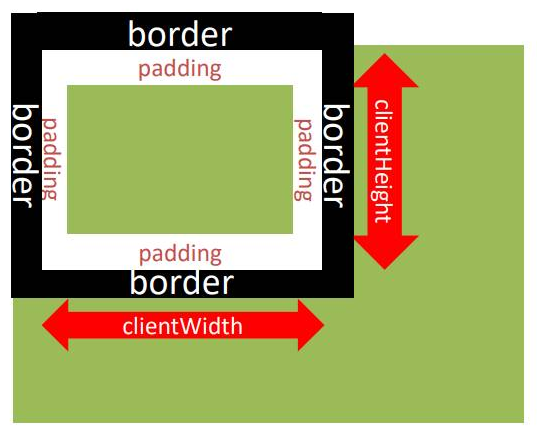

同课公开练习 `14-页面尺寸事件.html`：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
  <style>
    div {
      display: inline-block;
      width: 200px;
      height: 200px;
      background-color: pink;
      padding: 10px;
    }
  </style>
</head>

<body>
  <div>123</div>
  <script>
    const div = document.querySelector('div')
    // 通过clientWidth和clientHeight可以得到元素的内容区域宽度和高度
    console.log(div.clientWidth)
    // 通过offsetWidth和offsetHeight可以得到元素包围盒的宽度和高度 包括padding border margin
    console.log(div.offsetWidth)
    // resize 浏览器窗口大小发生变化时触发的事件
    window.addEventListener('resize', function () {
      console.log(1)
    })
  </script>
</body>

</html>
```

> 原注释把 `clientWidth` 说成内容区域宽度、把 `offsetWidth` 说成包含 `margin`，都不准确。本例未设置边框、采用默认 `content-box`，所以 `200 + 10 × 2 = 220`，两个宽度都应为 220；若添加边框，`offsetWidth` 会包含边框，`clientWidth` 不包含。

### 4.7 讲义案例：分析 Rem 基准值

讲义以 `flexible.js` 的核心思路说明 `resize` 的用途：把页面宽度分成十份，设置根 `html` 的字号，页面尺寸改变时重新计算。`rem` 相对于根元素字号；当前页面宽 375 像素时，这个示例把 `1rem` 设为 37.5 像素。

讲义第 47 页代码（按原图核对，属于演示的核心片段）：

```javascript
// 声明一个计算字号的函数
const setFontSize = function () {
  // 获取 html 元素
  const html = document.documentElement
  // 获取 html 元素的宽度
  const clientWidth = html.clientWidth
  // html 根字号设置： 当前页面宽度（html元素） / 10 划分为10等份
  html.style.fontSize = clientWidth / 10 + 'px'
}
// 页面加载先调用执行一次
setFontSize()
// 如果页面尺寸发生变化，则重新执行函数，重新计算
window.addEventListener('resize', setFontSize)
```

先执行 `setFontSize()` 完成初始设置，再把函数本身作为 `resize` 的回调。注册时写 `setFontSize`，不是 `setFontSize()`，否则传入的会是调用结果。

## 5. 元素尺寸与位置

### 5.1 `offsetWidth` 与 `offsetHeight`

如果一直手工写死滚动阈值，布局变化后就容易出错。课程开始改用元素实际的尺寸和位置。

`offsetWidth` / `offsetHeight` 获取元素布局中的边框盒宽高，包括内容、`padding`、`border` 以及占据布局空间的滚动条，不包括 `margin`。得到数字，属性只读。

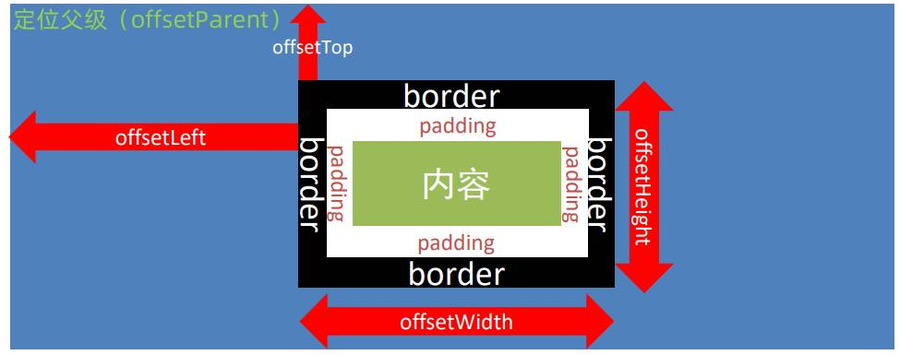

讲义说“盒子隐藏时结果为 0”，这里需区分：自身或祖先 `display: none` 导致没有布局盒时结果为 0；`opacity: 0`、`visibility: hidden` 仍保留布局，通常仍能得到尺寸。

### 5.2 `offsetLeft`、`offsetTop` 和 `offsetParent`

`offsetLeft` / `offsetTop` 获取元素相对 `offsetParent` 的左、上偏移，也是只读数字。课程用“定位父级”解释常见的 `offsetParent`：通常为最近具有定位的祖先；它不一定是直接父元素，也不能把所有 `offsetTop` 都当成相对文档的距离。

同课公开练习 `15-offsetLeft.html`：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
  <style>
    div {
      position: relative;
      width: 200px;
      height: 200px;
      background-color: pink;
      margin: 100px;
    }

    p {
      width: 100px;
      height: 100px;
      background-color: red;
      margin: 50px;
    }
  </style>
</head>

<body>
  <div>
    <p>123</p>
  </div>
  <script>
    const div = document.querySelector('div')
    const p = document.querySelector('p')
    // 元素的左内边距 到 元素的左边框的距离
    // 如果祖先元素有定位属性 则以最近的定位祖先元素的左边框为参考点
    // 否则以body元素的左边框为参考点
    console.log(p.offsetLeft)
  </script>
</body>

</html>
```

`div` 设置 `position: relative`，所以 `p.offsetParent` 是该 `div`，输出 `p.offsetLeft` 应为 50。原注释“元素左内边距到左边框”不准确；应理解为元素边框盒相对 `offsetParent` 内侧参考边的布局偏移。`offsetParent` 还存在表格元素等特殊规则，实际使用时可以读取该属性确认。

想移动元素应修改相应样式，例如 `style.left`，不能给 `offsetLeft` 赋值。本课固定导航与滑块就是读取 offset，修改 style。

### 5.3 案例：滚到秒杀模块时滑入固定导航

讲义称“仿京东固定导航栏”，公开练习文件名为 `16-仿新浪固定头部.html`。它们的核心要求一致：页面滚动到秒杀模块，顶部固定导航滑入；往上回到模块前，导航滑出。

1. 导航使用 `position: fixed`，初始 `top: -80px`，并设置过渡。
2. `scroll` 回调读取页面滚动距离。
3. 与秒杀模块的 `offsetTop` 比较。
4. 达到位置令导航 `top = '0px'`，否则回到 `'-80px'`。

同课公开练习完整页面：

```html
<!DOCTYPE html>
<html lang="en">

<head>
    <meta charset="UTF-8">
    <meta http-equiv="X-UA-Compatible" content="IE=edge">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Document</title>
    <style>
        * {
            margin: 0;
            padding: 0;
            box-sizing: border-box;
        }

        .content {
            overflow: hidden;
            width: 1000px;
            height: 3000px;
            background-color: pink;
            margin: 0 auto;
        }

        .backtop {
            display: none;
            width: 50px;
            left: 50%;
            margin: 0 0 0 505px;
            position: fixed;
            bottom: 60px;
            z-index: 100;
        }

        .backtop a {
            height: 50px;
            width: 50px;
            background: url(./images/bg2.png) 0 -600px no-repeat;
            opacity: 0.35;
            overflow: hidden;
            display: block;
            text-indent: -999em;
            cursor: pointer;
        }

        .header {
            position: fixed;
            top: -80px;
            left: 0;
            width: 100%;
            height: 80px;
            background-color: purple;
            text-align: center;
            color: #fff;
            line-height: 80px;
            font-size: 30px;
            transition: all .3s;
        }

        .sk {
            width: 300px;
            height: 300px;
            background-color: skyblue;
            margin-top: 500px;
        }
    </style>
</head>

<body>
    <div class="header">我是顶部导航栏</div>
    <div class="content">
        <div class="sk">秒杀模块</div>
    </div>
    <div class="backtop">
        <img src="./images/close2.png" alt="">
        <a href="javascript:;"></a>
    </div>
    <script>
        const sk = document.querySelector('.sk')
        const header = document.querySelector('.header')
        // 1. 页面滚动事件
        window.addEventListener('scroll', function () {
            // 当页面滚动到 秒杀模块 时 固定顶部导航栏 改变头部的top值
            // 页面被卷去的头部 >= 秒杀模块的位置 offsetTop
            const n = document.documentElement.scrollTop
            header.style.top = n >= sk.offsetTop ? 0 : -80 + ' px'
        })
    </script>
</body>

</html>
```

> 原代码 `-80 + ' px'` 会得到带空格的 `'-80 px'`，不是合法的 CSS 长度。导航滑入后向上滚动，滑出分支不能恢复原位置。

**修正示例**：仅替换该赋值行即可，其他部分沿用原页面：

```javascript
header.style.top = n >= sk.offsetTop ? '0px' : '-80px'
```

本页秒杀模块的 `offsetParent` 是 `body`，可按课程页面结构直接和页面滚动距离比较。若以后给其祖先增加定位，需要重新核对坐标参照。讲义分析中“移动秒杀模块的顶部位置”表述不准确；本例真正修改的是 **header 导航**的 `top`，秒杀模块只提供触发位置。

### 5.4 案例：bilibili 点击小滑块移动

需求：点击导航链接，下方红色滑块跟着移到该链接左侧位置。把事件委托给父级，取当前链接的 `offsetLeft`，赋给滑块的 `style.left`，再用 CSS 过渡。

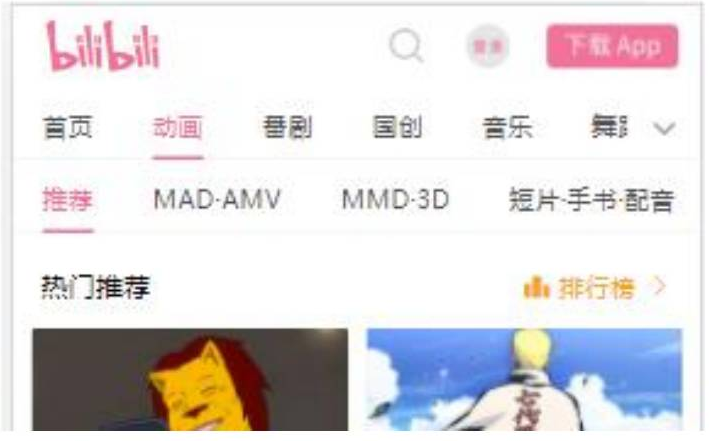

下面是依据讲义的**整理示例**，用简化结构展示本日逻辑，不冒充未下载的 `04-m-bilibili/index.html`：

```html
<!DOCTYPE html>
<html lang="zh-CN">
<head>
  <meta charset="UTF-8">
  <title>导航滑块</title>
  <style>
    .nav { position: relative; display: flex; gap: 24px; width: max-content; }
    .nav a { padding-bottom: 10px; color: #333; text-decoration: none; }
    .line {
      position: absolute;
      left: 0;
      bottom: 0;
      width: 32px;
      height: 2px;
      background: #fb7299;
      transition: left .3s;
    }
  </style>
</head>
<body>
  <nav class="nav">
    <a href="javascript:;">首页</a>
    <a href="javascript:;">动画</a>
    <a href="javascript:;">番剧</a>
    <a href="javascript:;">国创</a>
    <a href="javascript:;">音乐</a>
    <span class="line"></span>
  </nav>
  <script>
    const nav = document.querySelector('.nav')
    const line = document.querySelector('.line')
    nav.addEventListener('click', function (e) {
      if (e.target.tagName === 'A') {
        line.style.left = e.target.offsetLeft + 'px'
      }
    })
  </script>
</body>
</html>
```

链接与滑块共用 `.nav` 作为位置参照，链接的 `offsetLeft` 才能直接用作滑块的 `left`。读取时得到数字，赋 CSS 长度时加 `'px'`。依次点击链接，红线应移动到对应链接下面。

### 5.5 `getBoundingClientRect()`：相对视口的位置

`元素.getBoundingClientRect()` 返回一个 `DOMRect`，包含元素的大小及其相对**视口**的位置。视口就是浏览器当前可见的页面区域，和文档完整长度、定位祖先的位置参照不同。

同课公开练习 `17-getBoundingClientRect()获取相对于视口位置.html`：

```html
<!DOCTYPE html>
<html lang="zh-CN">

<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Document</title>
  <style>
    div {
      width: 200px;
      height: 200px;
      background-color: pink;
      margin: 100px;
    }
  </style>
</head>

<body>
  <div></div>
  <script>
    const div = document.querySelector('div')
    // 该方法返回元素的大小及其相对于 视口 的位置
    console.log(div.getBoundingClientRect())
  </script>
</body>

</html>
```

在控制台展开结果，可查看 `x`、`y`、`left`、`top`、`right`、`bottom`、`width`、`height`。页面滚动后重新调用，普通页面元素相对视口的 `top` 会改变；返回对象是调用当时的结果，需要重新调用才能得到新位置。

### 5.6 本日尺寸与位置对照

| 属性或方法 | 取得的量 | 参照或范围 | 可读写 |
| --- | --- | --- | --- |
| `scrollTop` / `scrollLeft` | 被卷去的上侧 / 左侧距离 | 对应滚动容器 | 读写 |
| `clientWidth` / `clientHeight` | 可见内部宽高 | 内容与 padding，排除 border、margin、占位滚动条 | 只读 |
| `offsetWidth` / `offsetHeight` | 布局边框盒宽高 | 内容、padding、border、占位滚动条，不含 margin | 只读 |
| `offsetLeft` / `offsetTop` | 左 / 上布局偏移 | `offsetParent` | 只读 |
| `getBoundingClientRect()` | 元素矩形大小与位置 | 相对视口 | 方法返回当前矩形 |

## 6. 综合案例：电梯导航

### 6.1 先拆成三个功能

页面右侧的小导航叫“电梯导航”：点击一个小模块，页面滚动到对应大模块；手动滚动页面时，小导航也会同步当前模块的选中状态。

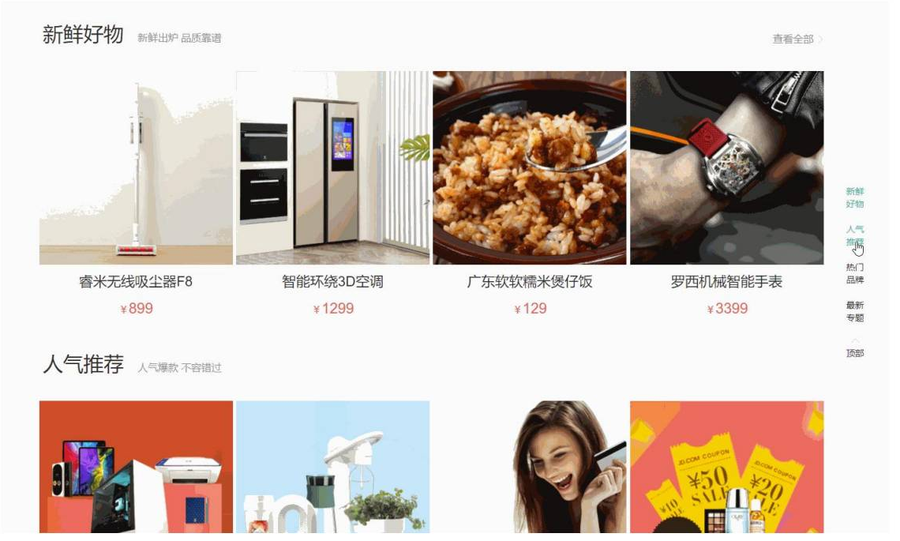

按课程顺序实现三个功能：

1. 页面滚到对应区域时显示电梯，点击“顶部”返回顶部。
2. 点击小导航，选中当前项，并滚到对应大模块。
3. 手动滚动到不同区间，同步小导航的 `active`。

这里使用同课公开练习 `电梯导航/电梯导航.html`。页面原本已引入 `css/common.css`、`css/index.css`，并包含小兔鲜儿的商品图片与四个大模块；本节保留交互相关结构和完整脚本，商品列表的重复展示内容不另抄。

### 6.2 用自定义名称连接小导航和大模块

原页面的电梯结构：

```html
  <!-- 电梯 -->
  <div class="xtx-elevator">
    <ul class="xtx-elevator-list">
      <li><a href="javascript:;" data-name="new">新鲜好物</a></li>
      <li><a href="javascript:;" data-name="popular">人气推荐</a></li>
      <li><a href="javascript:;" data-name="brand">热门品牌</a></li>
      <li><a href="javascript:;" data-name="topic">最新专题</a></li>
      <li><a href="javascript:;" id="backTop"><i class="sprites"></i>顶部</a></li>
    </ul>
  </div>
```

| 小导航 `data-name` | 对应大模块类名 | 页面模块 |
| --- | --- | --- |
| `new` | `.xtx_goods_new` | 新鲜好物 |
| `popular` | `.xtx_goods_popular` | 人气推荐 |
| `brand` | `.xtx_goods_brand` | 热门品牌 |
| `topic` | `.xtx_goods_topic` | 最新专题 |

返回顶部链接使用 `id="backTop"`，没有 `data-name`。委托处理中同时检查目标为 `A` 且有 `dataset.name`，这样它不会进入模块跳转分支。

原 `css/index.css` 中与电梯交互有关的样式：

```css
.xtx-elevator {
  position: fixed;
  left: 50%;
  top: 280px;
  z-index: 999;
  margin-left: 640px;
  opacity: 0;
  transition: all .5s;
}

.xtx-elevator .xtx-elevator-list {
  width: 60px;
  height: 300px;
  background: #fff;
  float: right;
  border: 1px solid #f5f5f5;
  position: relative;
}

.xtx-elevator .xtx-elevator-list li {
  height: 60px;
  padding: 15px;
}

.xtx-elevator .xtx-elevator-list li a {
  width: 30px;
  height: 30px;
  display: block;
}

.xtx-elevator .xtx-elevator-list li a:hover,
.xtx-elevator .xtx-elevator-list li a.active {
  color: #27BA9B;
}

.xtx-elevator .xtx-elevator-list li a i {
  display: block;
  width: 16px;
  height: 16px;
  position: relative;
  left: 4px;
  background-position: 8px -106px;
  font-size: 20px;
  transform: rotate(-90deg);
}
```

导航固定在视口侧边，初始 `opacity: 0`，滚动时通过透明度显隐；`active` 用颜色表达选中状态。原练习页面内容较宽，在较窄窗口中右侧电梯可能超出可见区域，需要足够宽的窗口观察原布局。

该样式文件开头还设置了页面平滑滚动，原代码如下：

```css
/* 页面滑动 */
html {
  /* 页面滑动平滑 */
  scroll-behavior: smooth;
}
```

因此点击模块或返回顶部时，页面会逐渐移动。滚动途中，第三模块的 `scroll` 回调仍按经过的区域更新选中项；观察或验证最终状态，要等页面滚动结束。

### 6.3 第一步：电梯显隐与返回顶部

第一模块放进立即执行函数 `(function () { ... })();`，形成局部作用域，避免与第二模块的变量互相影响。两个立即执行函数相邻时注意分号，原代码已在第一组末尾加分号。

滚动回调读取根元素的 `scrollTop`，与 `.xtx_entry` 的 `offsetTop` 比较，决定电梯透明度；点击 `#backTop` 调用 `window.scrollTo(0, 0)`。

原注释保留了“300px”的早期方案，但当前启用的表达式使用的是 **`entry.offsetTop`**，它会随着这个页面的布局位置变化。

### 6.4 第二步：委托点击、排他选中、跳转模块

只在 `.xtx-elevator-list` 注册一次点击。收到有效模块链接后：

1. 查询旧的 `.active`；初始可能没有选中项，先判断再删除。
2. 给真实点击的 `e.target` 添加 `active`。
3. 读取 `e.target.dataset.name`。
4. 用模板字符串 `.xtx_goods_${名称}` 找到对应大模块。
5. 把该模块的 `offsetTop` 赋给 `document.documentElement.scrollTop`。

> `querySelector()` 找不到元素会返回 `null`。本例必须保留 `if (old)`，否则初次点击就可能在 `null.classList` 处报错。

### 6.5 第三步：页面滚动时同步当前模块

每次滚动先清除旧的 `active`，再取得四个大模块与当前滚动距离，判断当前区间：

| 滚动距离 `n` 的区间 | 应选中的导航 |
| --- | --- |
| `n < news.offsetTop` | 无模块选中 |
| `news.offsetTop <= n < popular.offsetTop` | 新鲜好物 |
| `popular.offsetTop <= n < brand.offsetTop` | 人气推荐 |
| `brand.offsetTop <= n < topic.offsetTop` | 热门品牌 |
| `n >= topic.offsetTop` | 最新专题 |

下界包含、上界不包含，边界处不会同时选中两个模块。最后一项只判断下界，没有再增加一个不存在的下一模块。原页面“分类商品”位于热门品牌和最新专题之间，所以这段区间判断在分类商品区域仍会选中“热门品牌”，这与代码范围一致。

### 6.6 公开练习的完整交互脚本

以下完整保留 `电梯导航/电梯导航.html` 的 `<script>` 内容，包括被注释的旧方案：

```javascript
    (function () {
      // 第一大模块，页面滑动可以显示和隐藏电梯导航
      const entry = document.querySelector('.xtx_entry')
      const elevator = document.querySelector('.xtx-elevator')
      // 1. 当页面滚动大于300px 就显示电梯导航
      // 2. 给页面添加滚动事件
      window, addEventListener('scroll', function () {
        const n = document.documentElement.scrollTop // 得到的是数字型 不带单位
        // if (n >= 300) {
        //   elevator.style.opacity = 1
        // } else {
        //   elevator.style.opacity = 0
        // }
        elevator.style.opacity = n >= entry.offsetTop ? 1 : 0
      })

      const backTop = document.querySelector('#backTop')
      // 点击返回顶部
      backTop.addEventListener('click', function () {
        // document.documentElement.scrollTop = 0
        window.scrollTo(0, 0)
      })
    })();

    (function () {
      // 第二大模块，点击页面可以滑动
      const list = document.querySelector('.xtx-elevator-list')
      list.addEventListener('click', function (e) {
        if (e.target.tagName === 'A' && e.target.dataset.name) {
          const old = document.querySelector('.xtx-elevator-list .active')
          // 如果原来有active类，就移除类，如果开始就没有对象，就不删除，不判断会报错
          if (old) old.classList.remove('active')
          e.target.classList.add('active')
          // 获得自定义属性
          // 根据小盒子的自定义属性值去选择对应的大盒子
          // 获得对应大盒子的 offsetTop
          const top = document.querySelector(`.xtx_goods_${e.target.dataset.name}`).offsetTop
          // 页面滑动到对应位置
          document.documentElement.scrollTop = top
        }
      })

      // 第二大模块，页面滚动到对应位置，小盒子也添加active类
      window.addEventListener('scroll', function () {
        const old = document.querySelector('.xtx-elevator-list .active')
        // 如果原来有active类，就移除类，如果开始就没有对象，就不删除，不判断会报错
        if (old) old.classList.remove('active')
        // 判断页面当前滑动的位置，选择小盒子
        // 获取4个大盒子
        const news = document.querySelector('.xtx_goods_new')
        const popular = document.querySelector('.xtx_goods_popular')
        const brand = document.querySelector('.xtx_goods_brand')
        const topic = document.querySelector('.xtx_goods_topic')
        // 获得当前页面滑动的位置
        const n = document.documentElement.scrollTop
        // 判断当前位置是否在4个大盒子的范围内
        if (n >= news.offsetTop && n < popular.offsetTop) {
          // 属性选择器 []
          list.querySelector(`[data-name="new"]`).classList.add('active')
        } else if (n >= popular.offsetTop && n < brand.offsetTop) {
          list.querySelector(`[data-name="popular"]`).classList.add('active')
        } else if (n >= brand.offsetTop && n < topic.offsetTop) {
          list.querySelector(`[data-name="brand"]`).classList.add('active')
        } else if (n >= topic.offsetTop) {
          list.querySelector(`[data-name="topic"]`).classList.add('active')
        }
      })
    })()
  
```

原脚本第一模块写了 `window, addEventListener(...)`。这是逗号表达式，在浏览器普通全局脚本中，后面的 `addEventListener` 可解析到全局方法而运行，但表意不清晰。**修正时把这一处改为 `window.addEventListener(...)`**，其余参数和函数体保持原样。

本例四个大模块及 `.xtx_entry` 的 `offsetParent` 为 `body`，页面结构支持直接把这些位置和根元素的滚动距离比较。迁移到带定位祖先的新页面时，应重新核对参照，不能只复制赋值行。

验证顺序：从页面顶部向下滚动观察电梯显现；依次点击四个模块，页面顶部应对齐对应模块，并只有一个链接为 `active`；在每个模块的起点前后滚动，选中项应按上表切换；点击“顶部”应回到 0，电梯隐藏且不再有模块选中。

## 7. 当天练习与作业资料范围

讲义第 67 页要求：

1. 整理今天笔记。
2. 电梯导航模块、全选反选都练习 3 遍。
3. 做测试题。
4. 完成作业。

已在分享中核实 `07-作业` 的文件清单：

| 文件或目录 | 已确认的内容 | 当前读取状态 |
| --- | --- | --- |
| `01-电梯导航.html` | 独立 HTML 文件 | 网盘原正文未取得；本篇已讲解讲义与公开练习的综合案例 |
| `02-仿新浪返回顶部/index.html` | 附有 `images` 目录 | 网盘原正文未取得 |
| `03-购物车加减操作.html` | 独立 HTML 文件 | 网盘原正文未取得 |
| `04-m-bilibili/index.html` | 附有 `css`、`fonts`、`images`、`less`、`favicon.ico` | 网盘原正文未取得；本篇已整理讲义的滑块逻辑 |

作业下载要求登录，HTML 文件没有提供可读的公开正文预览；原 Markdown、思维导图、测试题内容也尚未取得。本篇完整覆盖已读的 68 页讲义和上述同课公开练习，不能将整理示例或公开练习当作这些网盘作业的原题、原答案。